In [ ]:

import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from skimage.transform import resize
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)


### Datos de entrada

Este modelo se entrenó utilizando imágenes de DBT previamente procesadas y almacenadas en formato `.npy`.

Los archivos de imágenes deben ubicarse en `datos_dbt/Imagenes/` y las etiquetas en `datos_dbt/Etiquetas/`.

Para el entrenamiento y la evaluación, las imágenes se redimensionan a 224 × 224 píxeles y se transforman en vectores unidimensionales.

Los resultados mostrados corresponden a la ejecución experimental original. Su reproducción exacta requiere los mismos conjuntos de datos y condiciones de ejecución.

In [ ]:
# ==========================================
# 1. CONFIGURACIÓN DE RUTAS
# ==========================================

from pathlib import Path

# Carpeta donde se encuentran los datos originales
DATA_DIR = Path("./datos_dbt")

DATA_DIR1 = DATA_DIR / "Imagenes"
DATA_DIR2 = DATA_DIR / "Etiquetas"

# Carpeta para guardar resultados
CKPT_DIR = DATA_DIR / "checkpoints"
CKPT_DIR.mkdir(parents=True, exist_ok=True)

# ==========================================
# 2. CARGA DE DATASETS
# ==========================================

print("\n=== Cargando datasets ===")

X_train = np.load(os.path.join(DATA_DIR, "X_train_nuevo.npy"))
y_train = np.load(os.path.join(DATA_DIR2, "y_train_nuevo.npy"))

X_val = np.load(os.path.join(DATA_DIR, "X_val.npy"))
y_val = np.load(os.path.join(DATA_DIR2, "y_val.npy"))

X_test = np.load(os.path.join(DATA_DIR, "X_test_final.npy"))
y_test = np.load(os.path.join(DATA_DIR2, "y_test_final.npy"))

print("\nTrain:", X_train.shape)
print("Val  :", X_val.shape)
print("Test :", X_test.shape)

print("\nDistribución entrenamiento:")
print(np.bincount(y_train))

print("\nDistribución validación:")
print(np.bincount(y_val))

print("\nDistribución test:")
print(np.bincount(y_test))




=== Cargando datasets ===

Train: (3197, 512, 512, 1)
Val  : (400, 512, 512, 1)
Test : (400, 512, 512, 1)

Distribución entrenamiento:
[1600 1597]

Distribución validación:
[200 200]

Distribución test:
[200 200]


In [ ]:
# ==========================================
# 3. PREPROCESAMIENTO
# ==========================================

def resize_dataset(X, size=(224, 224)):

    resultado = np.empty(
        (len(X), size[0] * size[1]),
        dtype=np.float32
    )

    for i, img in enumerate(X):
        resultado[i] = resize(
            img,
            size,
            anti_aliasing=True
        ).flatten()

        if (i + 1) % 200 == 0:
            print(
                f"Procesadas {i+1}/{len(X)}",
                flush=True
            )

    return resultado

print("\n=== Preprocesando TRAIN ===")
X_train_small = resize_dataset(X_train)

print("\n=== Preprocesando VAL ===")
X_val_small = resize_dataset(X_val)

print("\n=== Preprocesando TEST ===")
X_test_small = resize_dataset(X_test)

# Liberar referencias a las imágenes originales
del X_train, X_val, X_test
gc.collect()

print("\nDimensiones finales:")
print("Train:", X_train_small.shape)
print("Val  :", X_val_small.shape)
print("Test :", X_test_small.shape)




=== Preprocesando TRAIN ===
Procesadas 200/3197
Procesadas 400/3197
Procesadas 600/3197
Procesadas 800/3197
Procesadas 1000/3197
Procesadas 1200/3197
Procesadas 1400/3197
Procesadas 1600/3197
Procesadas 1800/3197
Procesadas 2000/3197
Procesadas 2200/3197
Procesadas 2400/3197
Procesadas 2600/3197
Procesadas 2800/3197
Procesadas 3000/3197

=== Preprocesando VAL ===
Procesadas 200/400
Procesadas 400/400

=== Preprocesando TEST ===
Procesadas 200/400
Procesadas 400/400


NameError: name 'gc' is not defined

In [ ]:
# ==========================================
# 4. ENTRENAMIENTO SVM
# ==========================================

print("\n=== Entrenando SVM ===", flush=True)

svm = SVC(
    C=1,
    kernel="poly",
    degree=2,
    gamma="scale",
    coef0=0,
    class_weight=None,
    cache_size=100
)

svm.fit(X_train_small, y_train)

print("Entrenamiento finalizado.")




=== Entrenando SVM ===
Entrenamiento finalizado.



=== MATRIZ DE CONFUSIÓN - TEST ===
[[151  49]
 [111  89]]

=== REPORTE DE CLASIFICACIÓN ===
                 precision    recall  f1-score   support

Sin estructuras       0.58      0.76      0.65       200
Con estructuras       0.64      0.45      0.53       200

       accuracy                           0.60       400
      macro avg       0.61      0.60      0.59       400
   weighted avg       0.61      0.60      0.59       400


=== RESULTADOS SVM - TEST ===
Accuracy      : 0.6000
Sensibilidad  : 0.4450
Especificidad : 0.7550
Precision     : 0.6449
F1-score      : 0.5266
AUC           : 0.6435


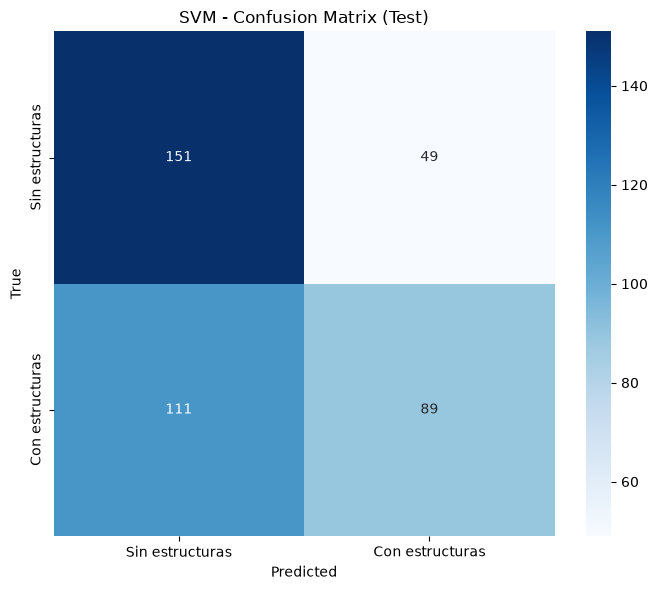

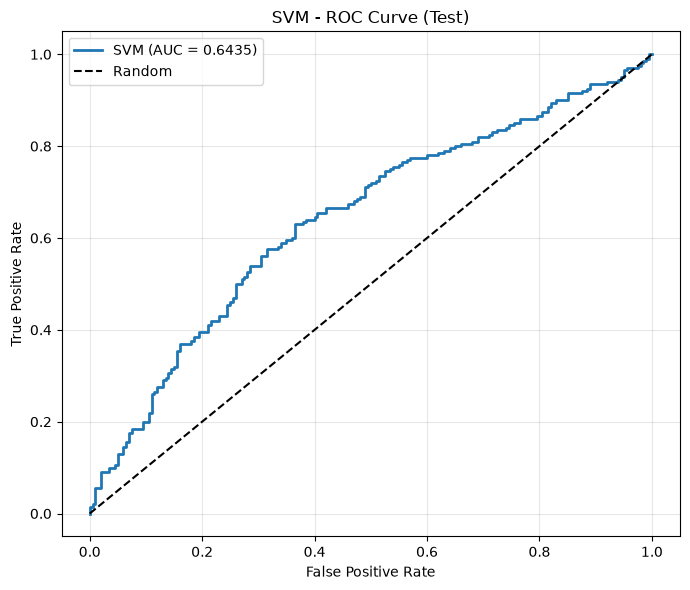

In [ ]:
# ==========================================
# 5. EVALUACIÓN EN TEST
# ==========================================

svm_predictions = svm.predict(X_test_small)

# Scores continuos para ROC
svm_scores = svm.decision_function(X_test_small)

# ==========================================
# 6. MATRIZ DE CONFUSIÓN
# ==========================================

svm_cm = confusion_matrix(
    y_test,
    svm_predictions,
    labels=[0, 1]
)

tn, fp, fn, tp = svm_cm.ravel()

print("\n=== MATRIZ DE CONFUSIÓN - TEST ===")
print(svm_cm)

print("\n=== REPORTE DE CLASIFICACIÓN ===")
print(
    classification_report(
        y_test,
        svm_predictions,
        labels=[0, 1],
        target_names=[
            "Sin estructuras",
            "Con estructuras"
        ],
        zero_division=0
    )
)

# ==========================================
# 7. MÉTRICAS
# ==========================================

accuracy = accuracy_score(y_test, svm_predictions)

sensibilidad = recall_score(
    y_test,
    svm_predictions,
    pos_label=1,
    zero_division=0
)

especificidad = (
    tn / (tn + fp) if (tn + fp) > 0 else np.nan
)

precision = precision_score(
    y_test,
    svm_predictions,
    pos_label=1,
    zero_division=0
)

f1 = f1_score(
    y_test,
    svm_predictions,
    pos_label=1,
    zero_division=0
)

auc = roc_auc_score(y_test, svm_scores)

print("\n=== RESULTADOS SVM - TEST ===")
print(f"Accuracy      : {accuracy:.4f}")
print(f"Sensibilidad  : {sensibilidad:.4f}")
print(f"Especificidad : {especificidad:.4f}")
print(f"Precision     : {precision:.4f}")
print(f"F1-score      : {f1:.4f}")
print(f"AUC           : {auc:.4f}")

# ==========================================
# 8. MATRIZ DE CONFUSIÓN - GRÁFICO
# ==========================================

plt.figure(figsize=(7, 6))

sns.heatmap(
    svm_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Sin estructuras",
        "Con estructuras"
    ],
    yticklabels=[
        "Sin estructuras",
        "Con estructuras"
    ]
)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("SVM - Confusion Matrix (Test)")

plt.tight_layout()

plt.savefig(
    os.path.join(
        CKPT_DIR,
        "SVM_confusion_matrix.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# 9. CURVA ROC
# ==========================================

fpr, tpr, thresholds = roc_curve(
    y_test,
    svm_scores
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"SVM (AUC = {auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Random"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("SVM - ROC Curve (Test)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        CKPT_DIR,
        "SVM_ROC.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
